# Which prompt wording works? — LLM prompt comparison

The same question ("does this support question contain sufficient information?") is asked in 9 different
wordings (`prompt_variants.py`), with two local LLMs (Qwen2.5-VL-7B and Qwen3-8B, both 4-bit, run with MLX).
Every variant gives one number per question: a score in [0, 1] where **higher = more likely insufficient**
(class 1), read from the first-token probabilities (no text is generated, so results are deterministic).

The 8 checklist prompts from `llm_judge.py` (product/version named? exact error quoted? ...) are compared
the same way in the second half.

How each prompt is judged, on the 64 labelled training questions:

| column | meaning | needs training? |
|---|---|---|
| `mass` | share of probability on the allowed answers (Yes/No or 1-5); low = the model ignored the format | no |
| `AUC` | does the score rank insufficient questions above sufficient ones? 0.5 = random, 1 = perfect | no |
| `F1 zero-shot @0.5` | F1 of class 1 if we simply predict "insufficient" when score >= 0.5 | no |
| `share pred 1` | fraction of questions predicted insufficient at 0.5 (true share is 0.34) | no |
| `F1 CV tuned` | 5x5 CV: logistic regression on this one score, threshold chosen inside each training part | yes (2 numbers + threshold) |

Reference: predicting "insufficient" for every question gives F1 0.51 — a prompt that does not beat this is not useful.
The few-shot variant shows 4 training questions as examples, so those 4 are left out of its evaluation.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score
from feats import SEED, cv_eval

train = pd.read_csv("data/train.csv")
y_all = train.set_index("id").sufficiency
MODELS = {"q25": "Qwen2.5-VL-7B", "q3": "Qwen3-8B"}
FEWSHOT_IDS = ["ID17", "ID350", "ID588", "ID113"]
print("F1 of predicting all 1:", round(f1_score(y_all, np.ones(len(y_all))), 3))

def evaluate(scores, masses, ids_exclude=()):
    """Score one prompt (a Series indexed by id, higher = more insufficient) on the labelled questions."""
    ids = [i for i in y_all.index if i not in ids_exclude]
    s, y = scores.loc[ids].values, y_all.loc[ids].values
    cv = cv_eval(LogisticRegression(C=1.0, class_weight="balanced", random_state=SEED), s.reshape(-1, 1), y)
    return {"mass": masses.loc[ids].mean(), "AUC": roc_auc_score(y, s),
            "F1 zero-shot @0.5": f1_score(y, s >= 0.5, zero_division=0), "share pred 1": (s >= 0.5).mean(),
            "F1 CV tuned": cv["f1_tuned"], "F1 CV std": cv["f1_tuned_std"]}

F1 of predicting all 1: 0.512


## Part 1 — wordings of the main question

In [2]:
rows, V = [], {}
for tag, model_name in MODELS.items():
    f = Path(f"features/prompt_variants_{tag}.csv")
    if not f.exists():
        print("not available yet:", f); continue
    d = pd.read_csv(f).set_index("id"); V[tag] = d
    for v in [c for c in d.columns if not c.endswith("_mass")]:
        r = evaluate(d[v], d[f"{v}_mass"], FEWSHOT_IDS if v == "v9_fewshot" else ())
        rows.append({"model": model_name, "prompt": v, **r})
    # average of all zero-shot variants (no selection, so no optimistic bias)
    zs = [c for c in d.columns if c.startswith("v") and not c.endswith("_mass") and c != "v9_fewshot"]
    r = evaluate(d[zs].mean(1), d[[c + "_mass" for c in zs]].mean(1))
    rows.append({"model": model_name, "prompt": "mean of v1-v8", **r})
variants = pd.DataFrame(rows)
variants.round(3)

,model,prompt,mass,AUC,F1 zero-shot @0.5,share pred 1,F1 CV tuned,F1 CV std
0,Qwen2.5-VL-7B,v1_bare,0.999,0.576,0.525,0.609,0.441,0.144
1,Qwen2.5-VL-7B,v2_definition,0.999,0.639,0.542,0.578,0.512,0.095
2,Qwen2.5-VL-7B,v3_negative,0.999,0.723,0.600,0.594,0.540,0.179
3,Qwen2.5-VL-7B,v4_engineer,0.999,0.611,0.512,0.938,0.467,0.079
4,Qwen2.5-VL-7B,v5_checklist,0.999,0.709,0.545,0.688,0.543,0.127
5,Qwen2.5-VL-7B,v6_strict,0.999,0.670,0.541,0.812,0.518,0.090
6,Qwen2.5-VL-7B,v7_annotator,1.000,0.672,0.439,0.297,0.574,0.135
7,Qwen2.5-VL-7B,v8_scale,0.999,0.648,0.222,0.078,0.462,0.132
8,Qwen2.5-VL-7B,v9_fewshot,1.000,0.633,0.400,0.333,0.471,0.139
9,Qwen2.5-VL-7B,mean of v1-v8,0.999,0.697,0.525,0.609,0.609,0.136


In [3]:
# The full prompt texts, for reference
for tag in V:
    spec = json.load(open(f"features/prompt_variants_{tag}.json"))
    if tag == next(iter(V)):
        for k, v in spec["variants"].items():
            print(f"--- {k} ({v['kind']})\nSYSTEM: {v['system']}\nUSER:   {v['user']}\n")

--- v1_bare (yesno_pos)
SYSTEM: Answer only Yes or No.
USER:   Support question:
"""
{q}
"""
Is this question sufficient? Answer Yes or No.

--- v2_definition (yesno_pos)
SYSTEM: You review tech-support forum questions. A question is SUFFICIENT if it provides enough relevant details to understand the issue and begin troubleshooting. It is INSUFFICIENT if it lacks important details needed for effective troubleshooting. Answer only Yes or No.
USER:   Support question:
"""
{q}
"""
Is this question SUFFICIENT? Answer Yes or No.

--- v3_negative (yesno_neg)
SYSTEM: You review tech-support forum questions. A question is SUFFICIENT if it provides enough relevant details to understand the issue and begin troubleshooting. It is INSUFFICIENT if it lacks important details needed for effective troubleshooting. Answer only Yes or No.
USER:   Support question:
"""
{q}
"""
Does this question LACK important details needed for effective troubleshooting? Answer Yes or No.

--- v4_engineer (yesno_neg)
SY

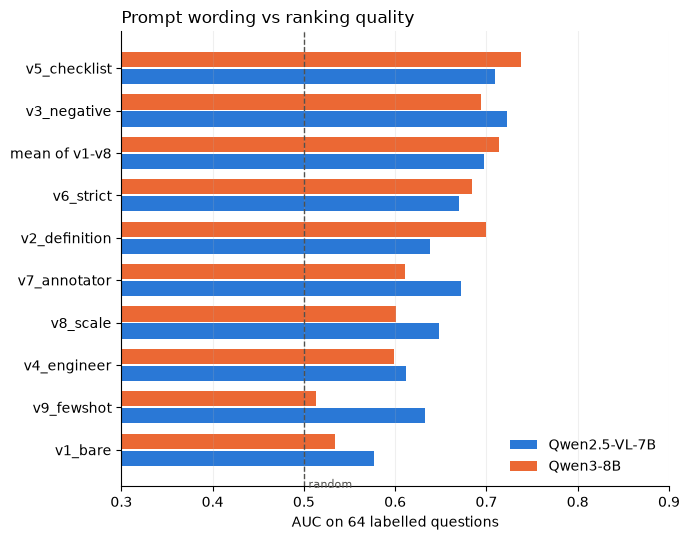

In [4]:
# AUC per prompt and model (0.5 = no better than random ordering)
if len(variants):
    piv = variants.pivot(index="prompt", columns="model", values="AUC")
    piv = piv.loc[piv.mean(1).sort_values().index]
    colors = {"Qwen2.5-VL-7B": "#2a78d6", "Qwen3-8B": "#eb6834"}
    fig, ax = plt.subplots(figsize=(7, 0.45 * len(piv) + 1))
    h = 0.8 / len(piv.columns)
    for j, m in enumerate(piv.columns):
        ax.barh(np.arange(len(piv)) + (j - (len(piv.columns) - 1) / 2) * h, piv[m], height=h * 0.9,
                color=colors.get(m), label=m)
    ax.axvline(0.5, color="#52514e", lw=1, ls="--"); ax.text(0.505, -0.9, "random", color="#52514e", fontsize=8)
    ax.set_yticks(range(len(piv))); ax.set_yticklabels(piv.index)
    ax.set_xlim(0.3, 0.9); ax.set_xlabel("AUC on 64 labelled questions")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", alpha=0.2)
    ax.legend(frameon=False, loc="lower right"); ax.set_title("Prompt wording vs ranking quality", loc="left")
    plt.tight_layout(); plt.show()

## Part 2 — checklist prompts (`llm_judge.py`)

In [5]:
rows, C = [], {}
for tag, model_name in MODELS.items():
    f = Path(f"features/llm_{tag}.csv")
    if not f.exists():
        print("not available yet:", f); continue
    d = pd.read_csv(f).set_index("id"); C[tag] = d
    for c in [c for c in d.columns if not c.endswith("_mass")]:
        # For prompts where "Yes" means GOOD information, flip so that higher = more insufficient
        positive = c in ("sufficient", "product_version", "clear_symptom", "error_text", "tried_steps")
        s = 1 - d[c] if positive else d[c]
        rows.append({"model": model_name, "prompt": c + (" (flipped)" if positive else ""), **evaluate(s, d[f"{c}_mass"])})
checklist = pd.DataFrame(rows)
checklist.round(3)

,model,prompt,mass,AUC,F1 zero-shot @0.5,share pred 1,F1 CV tuned,F1 CV std
0,Qwen2.5-VL-7B,sufficient (flipped),1.000,0.610,0.440,0.438,0.464,0.125
1,Qwen2.5-VL-7B,need_more,0.999,0.685,0.627,0.453,0.628,0.156
2,Qwen2.5-VL-7B,product_version (flipped),1.000,0.690,0.535,0.766,0.539,0.129
3,Qwen2.5-VL-7B,clear_symptom (flipped),1.000,0.600,0.480,0.438,0.471,0.086
4,Qwen2.5-VL-7B,error_text (flipped),0.999,0.668,0.518,0.984,0.460,0.107
5,Qwen2.5-VL-7B,tried_steps (flipped),1.000,0.563,0.528,0.781,0.478,0.071
6,Qwen2.5-VL-7B,missing_attachment,1.000,0.687,0.000,0.000,0.483,0.088
7,Qwen2.5-VL-7B,vague,0.999,0.671,0.375,0.156,0.593,0.135
8,Qwen3-8B,sufficient (flipped),1.000,0.670,0.583,0.406,0.581,0.134
9,Qwen3-8B,need_more,1.000,0.691,0.500,0.219,0.417,0.159


## Part 3 — second prompt set (`prompts_v2.py`): plain-English questions

The first attempt (Parts 1-2) had awkward wordings ("Is this question sufficient?" — sufficient for what?,
capitals, "label 1" jargon, convoluted checklist items). The second set uses one template and plain questions:
W1-W9 = ways of asking the main question, C1-C12 = one specific piece of information each.
All scores again point the same way (higher = more likely insufficient).

In [6]:
rows, P2 = [], {}
for tag, model_name in MODELS.items():
    f = Path(f"features/prompts_v2_{tag}.csv")
    if not f.exists():
        print("not available yet:", f); continue
    d = pd.read_csv(f).set_index("id"); P2[tag] = d
    spec = json.load(open(f"features/prompts_v2_{tag}.json"))["prompts"]
    for c in [c for c in d.columns if not c.endswith("_mass")]:
        rows.append({"model": model_name, "prompt": c, "question": spec[c]["question"],
                     **evaluate(d[c], d[f"{c}_mass"])})
    W = [c for c in d.columns if c.startswith("W") and not c.endswith("_mass")]
    Cs = [c for c in d.columns if c.startswith("C") and not c.endswith("_mass")]
    rows.append({"model": model_name, "prompt": "mean of W1-W9", "question": "(average, no selection)",
                 **evaluate(d[W].mean(1), d[[w + "_mass" for w in W]].mean(1))})
    rows.append({"model": model_name, "prompt": "mean of C1-C12", "question": "(average, no selection)",
                 **evaluate(d[Cs].mean(1), d[[c + "_mass" for c in Cs]].mean(1))})
v2 = pd.DataFrame(rows)
v2.round(3)

,model,prompt,question,mass,AUC,F1 zero-shot @0.5,share pred 1,F1 CV tuned,F1 CV std
0,Qwen2.5-VL-7B,W1_direct,Does this question give enough information to ...,0.999,0.576,0.407,0.500,0.451,0.132
1,Qwen2.5-VL-7B,W2_missing,Is important information missing from this que...,0.999,0.716,0.541,0.234,0.619,0.133
2,Qwen2.5-VL-7B,W3_followup,"If you were answering this, would you need to ...",0.999,0.570,0.493,0.797,0.504,0.062
3,Qwen2.5-VL-7B,W4_reproduce,Could you try to reproduce or diagnose this pr...,1.000,0.463,0.512,1.000,0.510,0.038
4,Qwen2.5-VL-7B,W5_role,Does this question give enough information to ...,0.999,0.581,0.453,0.484,0.462,0.122
5,Qwen2.5-VL-7B,W6_definition,Does this question give enough information to ...,1.000,0.621,0.500,0.531,0.439,0.134
6,Qwen2.5-VL-7B,W7_expert,Could an expert reply with a useful answer str...,0.999,0.536,0.494,0.984,0.473,0.110
7,Qwen2.5-VL-7B,W8_next_step,Is it clear what the first troubleshooting ste...,0.999,0.510,0.475,0.906,0.496,0.072
8,Qwen2.5-VL-7B,W9_cause,Can you tell what is most likely causing this ...,0.999,0.529,0.524,0.969,0.507,0.052
9,Qwen2.5-VL-7B,C1_product,"Does the question say which product, device or...",0.999,0.648,0.462,0.469,0.535,0.115


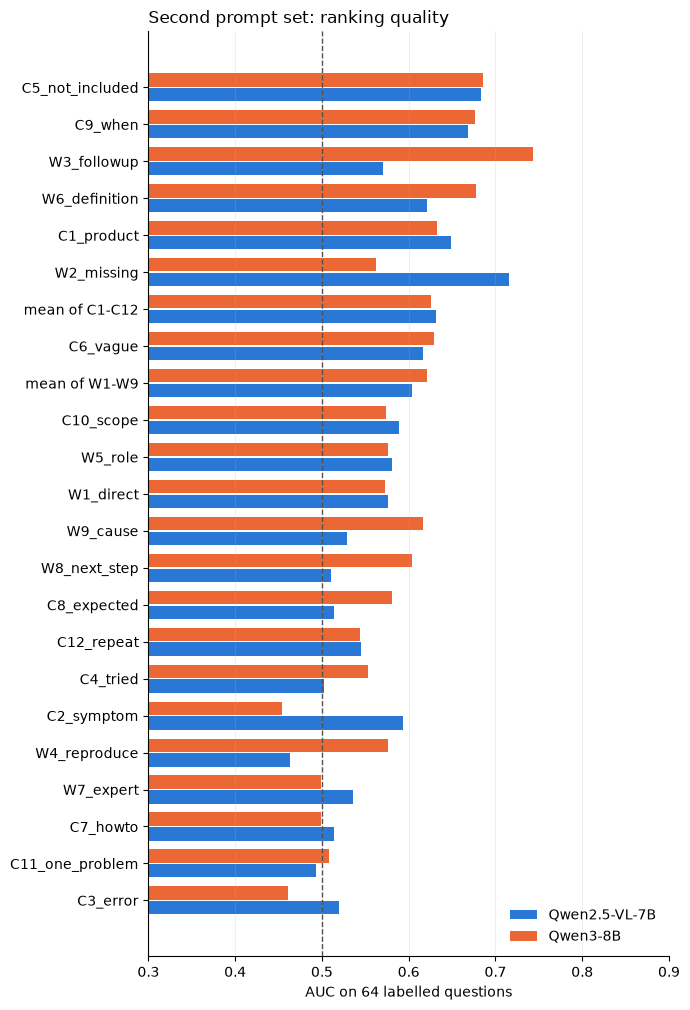

In [7]:
# AUC per new prompt and model
if len(v2):
    piv = v2.pivot(index="prompt", columns="model", values="AUC")
    piv = piv.loc[piv.mean(1).sort_values().index]
    colors = {"Qwen2.5-VL-7B": "#2a78d6", "Qwen3-8B": "#eb6834"}
    fig, ax = plt.subplots(figsize=(7, 0.4 * len(piv) + 1))
    h = 0.8 / len(piv.columns)
    for j, m in enumerate(piv.columns):
        ax.barh(np.arange(len(piv)) + (j - (len(piv.columns) - 1) / 2) * h, piv[m], height=h * 0.9,
                color=colors.get(m), label=m)
    ax.axvline(0.5, color="#52514e", lw=1, ls="--")
    ax.set_yticks(range(len(piv))); ax.set_yticklabels(piv.index)
    ax.set_xlim(0.3, 0.9); ax.set_xlabel("AUC on 64 labelled questions")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", alpha=0.2)
    ax.legend(frameon=False, loc="lower right"); ax.set_title("Second prompt set: ranking quality", loc="left")
    plt.tight_layout(); plt.show()

In [8]:
# First attempt vs second set, per model: average quality of all prompts and of the best one
cmp = []
for name, df_ in [("1st attempt: wordings", variants), ("1st attempt: checklist", checklist), ("2nd set", v2)]:
    if not len(df_): continue
    single = df_[~df_.prompt.str.startswith("mean")]
    for m, g in single.groupby("model"):
        cmp.append({"set": name, "model": m, "n prompts": len(g), "mean AUC": g.AUC.mean(), "best AUC": g.AUC.max(),
                    "mean F1 CV": g["F1 CV tuned"].mean(), "best F1 CV": g["F1 CV tuned"].max(),
                    "n beating all-1 (0.51)": int((g["F1 CV tuned"] > 0.51).sum())})
pd.DataFrame(cmp).round(3)

,set,model,n prompts,mean AUC,best AUC,mean F1 CV,best F1 CV,n beating all-1 (0.51)
0,1st attempt: wordings,Qwen2.5-VL-7B,9,0.653,0.723,0.503,0.574,5
1,1st attempt: wordings,Qwen3-8B,9,0.630,0.738,0.523,0.580,6
2,1st attempt: checklist,Qwen2.5-VL-7B,8,0.647,0.690,0.514,0.628,3
3,1st attempt: checklist,Qwen3-8B,8,0.678,0.723,0.497,0.589,4
4,2nd set,Qwen2.5-VL-7B,21,0.571,0.716,0.490,0.619,4
5,2nd set,Qwen3-8B,21,0.582,0.744,0.504,0.597,10


## Summary

* **worked** = AUC clearly above 0.5 *and* F1 CV above the all-1 reference (0.51);
* **did not work** = AUC near 0.5, or the model ignored the format (low mass), or it predicts
  (almost) everything as one class at 0.5 (see `share pred 1`).

In [9]:
summary = pd.concat([variants.assign(group="1st wording"), checklist.assign(group="1st checklist"),
                     v2.assign(group="2nd set")], ignore_index=True)
summary["verdict"] = np.where((summary["AUC"] >= 0.6) & (summary["F1 CV tuned"] > 0.51), "worked",
                     np.where(summary["AUC"] >= 0.55, "weak", "did not work"))
summary.sort_values("AUC", ascending=False)[["group", "model", "prompt", "AUC", "F1 zero-shot @0.5",
                                             "share pred 1", "F1 CV tuned", "mass", "verdict"]].round(3)

,group,model,prompt,AUC,F1 zero-shot @0.5,share pred 1,F1 CV tuned,mass,verdict
61,2nd set,Qwen3-8B,W3_followup,0.744,0.609,0.375,0.597,1.000,worked
14,1st wording,Qwen3-8B,v5_checklist,0.738,0.577,0.469,0.570,1.000,worked
2,1st wording,Qwen2.5-VL-7B,v3_negative,0.723,0.600,0.594,0.540,0.999,worked
32,1st checklist,Qwen3-8B,error_text (flipped),0.723,0.630,0.500,0.589,1.000,worked
37,2nd set,Qwen2.5-VL-7B,W2_missing,0.716,0.541,0.234,0.619,0.999,worked
...,...,...,...,...,...,...,...,...,...
65,2nd set,Qwen3-8B,W7_expert,0.499,0.118,0.188,0.482,1.000,did not work
55,2nd set,Qwen2.5-VL-7B,C11_one_problem,0.493,0.318,0.344,0.491,0.999,did not work
39,2nd set,Qwen2.5-VL-7B,W4_reproduce,0.463,0.512,1.000,0.510,1.000,did not work
70,2nd set,Qwen3-8B,C3_error,0.460,0.512,0.938,0.500,1.000,did not work


In [10]:
summary.to_csv("logs/prompt_results.csv", index=False)
print("saved logs/prompt_results.csv")

saved logs/prompt_results.csv
